# Model 4: Wine quality classification with k nearest neighbours

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

A winery bottles thousands of litres of wine every season and, before it can label a batch as a premium or a table wine, a panel of tasters has to score it. Tasting is slow, expensive and subjective, while the laboratory measurements of the same wine, its acidity, its sugar, its alcohol, its sulphites, are cheap and available the day the batch is made. The question this notebook answers is whether the tasting score can be predicted from those measurements, so that the assistant of the project can answer "how good is this wine" from a lab sheet.

The dataset is the wine quality file of Cortez and colleagues, published on Kaggle by rajyellow46, with 6,497 Portuguese vinho verde wines, red and white. Each row has eleven laboratory measurements, the colour of the wine and the score the tasters gave it, an integer from 3 to 9.

The technique is k nearest neighbours, taught in week eight of the course. It does not fit an equation. To classify a new wine it finds the k wines in the training set whose measurements are closest to it and gives the new wine the score that is most common among those k. Two decisions make or break the method: on what scale the distance is measured, since a distance adds up differences across columns written in very different units, and how many neighbours k to consult. Both are worked out in this notebook.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Split, validation, evaluation and persistence
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             balanced_accuracy_score)
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', '..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns its folder, so the cell works unchanged on a local machine and in Google Colab.

In [2]:
path = kagglehub.dataset_download('rajyellow46/wine-quality')
print('Path to dataset files:', path)
wine = pd.read_csv(os.path.join(path, 'winequalityN.csv'))
wine.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/rajyellow46/wine-quality/versions/1


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


Each row is one wine. `type` says whether it is red or white. The next eleven columns are laboratory measurements: the three acidity columns and the pH describe how sour the wine is, `residual sugar` is the sugar left after fermentation in grams per litre, `chlorides` is salt, the two sulfur dioxide columns are the preservative in milligrams per litre, `density` is the mass of a litre in grams per cubic centimetre, `sulphates` is another preservative and `alcohol` is the percentage by volume. `quality` is the target, the median score of at least three tasters. The first wine is a white with 20.7 grams of sugar, a sweet wine, scored 6.

In [3]:
print("Rows and columns:", wine.shape)
wine.info()
print()
print("Missing values per column:")
print(wine.isna().sum()[wine.isna().sum() > 0])
print()
print("Duplicated rows:", wine.duplicated().sum())

Rows and columns: (6497, 13)
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB

Missing values per column:
fixed acidity       1

There are 6,497 wines and 13 columns. Seven columns have a few missing values, the most being 10 in `fixed acidity`, which on 6,497 rows is nothing, so they are filled with the median of their column in the preparation. What is not nothing is the count of duplicated rows: 1,168 wines, 18 percent of the file, are exact copies of another row across all thirteen columns.

For k nearest neighbours a duplicate is a specific danger. The method answers with the score of the closest wines, and the closest wine to a copy is its original, at distance zero. If a copy lands in the test set and its original in the training set, the model "predicts" the score by reading it off, which makes the test score better than the model. The copies are removed, keeping one row of each.

In [4]:
wine = wine.drop_duplicates().reset_index(drop=True)
print("Wines after removing duplicates:", len(wine))
wine.describe().round(3)

Wines after removing duplicates: 5329


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5319.000,5321.000,5326.000,5327.000,5327.000,5329.000,5329.000,5329.000,5320.000,5325.000,5329.000,5329.000
mean,7.217,0.344,0.319,5.054,0.057,30.060,114.189,0.995,3.224,0.533,10.549,5.796
std,1.319,0.168,0.147,4.504,0.037,17.816,56.781,0.003,0.160,0.150,1.186,0.880
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.240,1.800,0.038,16.000,75.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.300,0.310,2.700,0.047,28.000,116.000,0.995,3.210,0.510,10.400,6.000
75%,7.700,0.410,0.400,7.500,0.066,41.000,154.000,0.997,3.330,0.600,11.400,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


The file keeps 5,329 wines. The table lists, for each measurement, the mean, the standard deviation, the minimum, the quartiles and the maximum, and the row to read is the standard deviation, because it is the scale on which each column moves. `total sulfur dioxide` has a standard deviation of about 57 and runs from 6 to 440. `density` has a standard deviation of 0.003 and runs from 0.987 to 1.039. `chlorides` moves by 0.035. This is the scaling problem the technique depends on, and it is measured in the exploration section. The target `quality` has a mean of 5.8 and a median of 6, and its extremes, 3 and 9, are rare.

         Wines  Share %
quality                
3           30      0.6
4          206      3.9
5         1755     32.9
6         2327     43.7
7          857     16.1
8          149      2.8
9            5      0.1

quality   3    4     5     6    7    8  9
type                                     
red      10   53   577   535  167   17  0
white    20  153  1178  1792  690  132  5


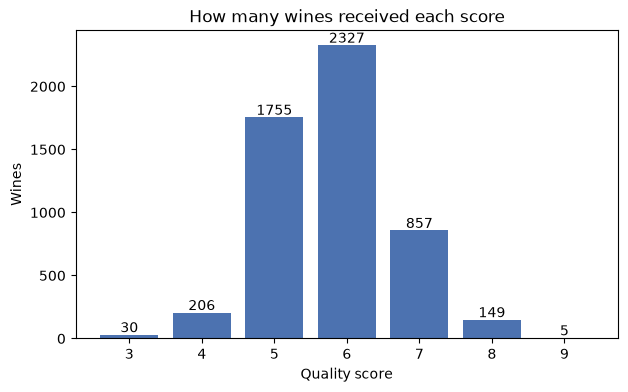

In [5]:
# The target, by score and by colour
counts = wine['quality'].value_counts().sort_index()
print(pd.DataFrame({'Wines': counts, 'Share %': (counts / len(wine) * 100).round(1)}))
print()
print(pd.crosstab(wine['type'], wine['quality']))

plt.figure(figsize=(7, 4))
plt.bar(counts.index.astype(str), counts.values, color='#4c72b0')
for i, value in enumerate(counts.values):
    plt.text(i, value + 20, str(value), ha='center')
plt.title('How many wines received each score')
plt.xlabel('Quality score')
plt.ylabel('Wines')
plt.show()

The chart counts the wines at each score. Two scores hold most of the file: 6 with 2,327 wines and 5 with 1,755, together 77 percent. Score 7 has 857, score 4 has 206, score 8 has 149, score 3 has 30 and score 9 has 5. The crosstab shows that whites are three times more numerous than reds and that every wine scored 9 is white.

This distribution is the central difficulty of the notebook. A method that votes among neighbours can only give a rare score if most of the neighbours have it, and a wine scored 9 has four other 9s in the whole file to be close to. So the seven-class model built first will not be able to find the extreme scores, and the notebook regroups them later.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration asks which measurements move with the score and on what scale each one is written. The preparation fills the few gaps, encodes the colour and splits the wines.

In [6]:
# Fill the few missing values with the median of each column and encode the colour
FILL_VALUES = {}
for column in wine.columns:
    if wine[column].isna().any():
        FILL_VALUES[column] = float(wine[column].median())
        wine[column] = wine[column].fillna(FILL_VALUES[column])
print("Fill values used:", FILL_VALUES)

wine['type'] = (wine['type'] == 'white').astype(int)
FEATURES = [c for c in wine.columns if c != 'quality']
TARGET = 'quality'
print("Missing values left:", int(wine.isna().sum().sum()))

Fill values used: {'fixed acidity': 7.0, 'volatile acidity': 0.3, 'citric acid': 0.31, 'residual sugar': 2.7, 'chlorides': 0.047, 'pH': 3.21, 'sulphates': 0.51}
Missing values left: 0


Every gap is now filled with the median of its column, the values are kept in `FILL_VALUES` so the API can apply the same ones, and `type` reads 1 for white and 0 for red. The twelve predictors are the eleven measurements plus the colour.

                      Pearson  Spearman
density                -0.327    -0.349
volatile acidity       -0.264    -0.251
chlorides              -0.202    -0.304
fixed acidity          -0.081    -0.105
residual sugar         -0.057    -0.029
total sulfur dioxide   -0.050    -0.058
pH                      0.040     0.053
sulphates               0.041     0.035
free sulfur dioxide     0.054     0.090
citric acid             0.099     0.117
type                    0.115     0.120
alcohol                 0.470     0.480


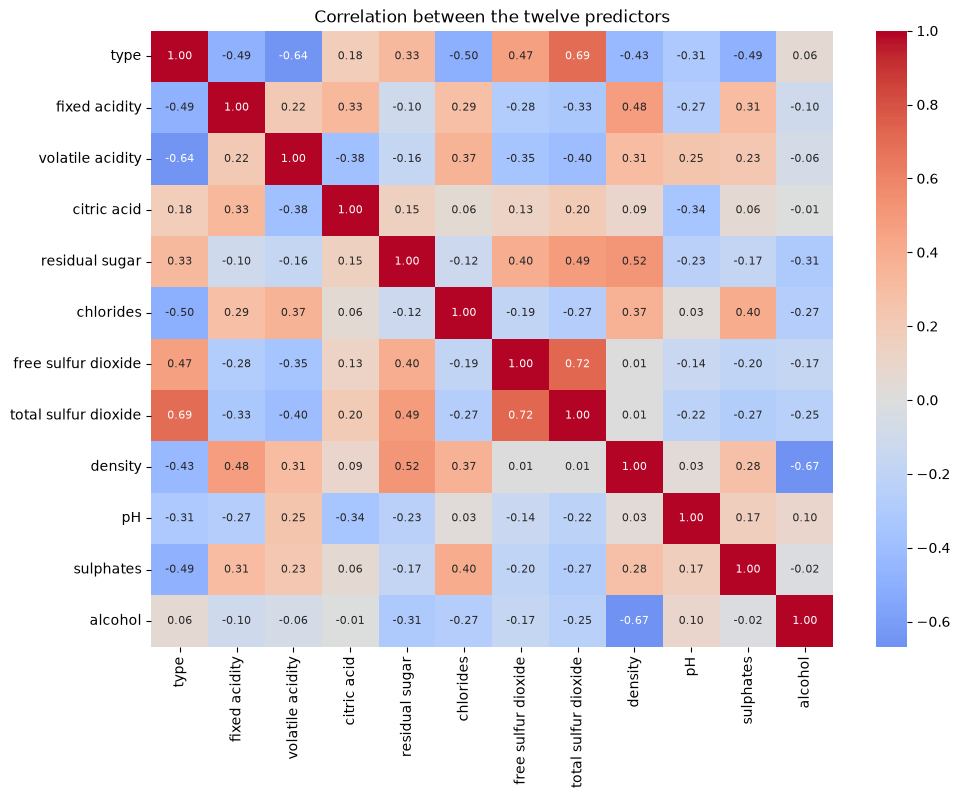

In [7]:
# Pearson measures how straight the relationship is, Spearman whether the ranking
# of one column follows the ranking of the other
correlation_target = pd.DataFrame({
    'Pearson': wine.corr()[TARGET],
    'Spearman': wine.corr(method='spearman')[TARGET],
}).drop(TARGET).sort_values('Pearson').round(3)
print(correlation_target)

plt.figure(figsize=(11, 8))
sns.heatmap(wine[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation between the twelve predictors')
plt.show()

The correlations with the score are weak across the board. Alcohol is the strongest at 0.47 in Pearson and 0.48 in Spearman, then density at -0.33, volatile acidity at -0.26 and chlorides at -0.20. Everything else is below 0.12 in absolute value. Alcohol and density are partly the same information, since alcohol is lighter than water and a wine with more alcohol is less dense, and the heatmap shows them at -0.69. No single measurement predicts the score well, which is why a method that looks at all twelve at once, like k nearest neighbours, is a reasonable choice, and why the accuracy will not be high.

The heatmap also shows the strongest pair among predictors, `free sulfur dioxide` with `total sulfur dioxide` at 0.72, which is arithmetic since the free part is inside the total, and `type` with `total sulfur dioxide` at 0.70, since whites carry more sulphites. None of this breaks the method: k nearest neighbours has no slopes to destabilise, a correlated pair only counts twice in the distance.

         alcohol  volatile acidity  density
quality                                    
3          10.15             0.415    0.996
4          10.10             0.385    0.995
5           9.60             0.340    0.996
6          10.50             0.270    0.994
7          11.50             0.280    0.992
8          12.20             0.280    0.992
9          12.50             0.270    0.990


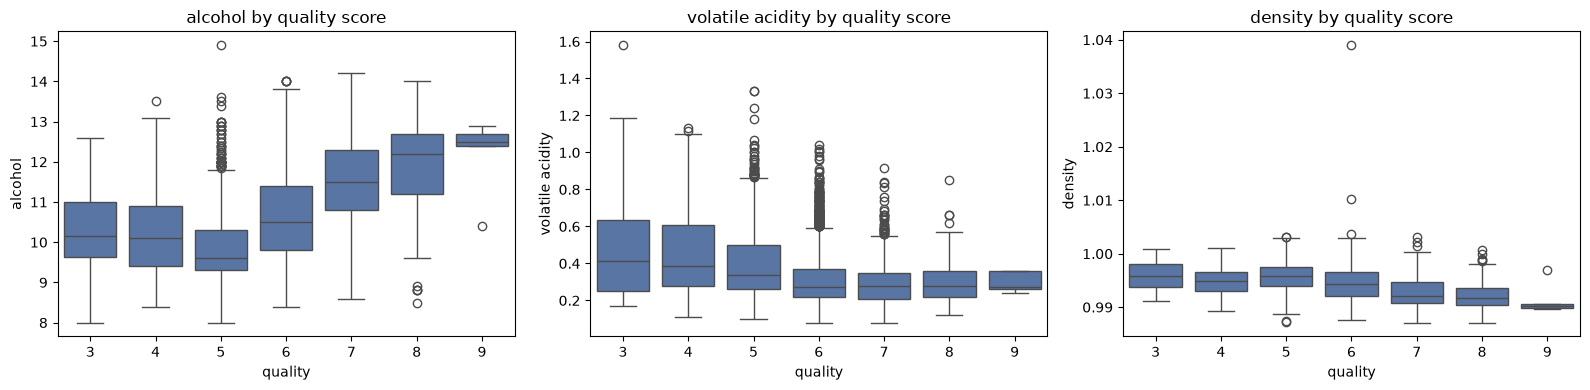

In [8]:
# The median of the three strongest measurements at each score
print(wine.groupby(TARGET)[['alcohol', 'volatile acidity', 'density']].median().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ['alcohol', 'volatile acidity', 'density']):
    sns.boxplot(data=wine, x=TARGET, y=column, ax=ax, color='#4c72b0')
    ax.set_title(column + ' by quality score')
plt.tight_layout()
plt.show()

Each panel is a row of box plots, one per score. The box holds the middle half of the wines of that score, the line inside is the median, the whiskers reach the values still close to the box and the dots beyond are the extremes.

Alcohol rises with the score in a clean staircase from score 5 upward: the median goes 9.6, 10.5, 11.5, 12.2 and 12.5 for scores 5 to 9. Below 5 it flattens, since the wines scored 3 and 4 are not weak wines but faulty ones. Volatile acidity, which is the vinegar smell, runs the other way, with the median falling from 0.415 at score 3 to 0.27 at score 9. Density follows alcohol in reverse. The boxes overlap heavily at every step, however: a wine with 11 percent alcohol can be a 5, a 6 or a 7, and that overlap is the ceiling of any model built on these measurements.

In [9]:
# The scale problem. A distance adds up the squared difference of each column,
# so each column weighs in proportion to its variance. This is that share
variances = wine[FEATURES].var()
weight = pd.DataFrame({
    'Standard deviation': wine[FEATURES].std().round(4),
    'Weight in a raw distance %': (variances / variances.sum() * 100).round(3),
    'Weight after scaling %': round(100 / len(FEATURES), 2),
}).sort_values('Weight in a raw distance %', ascending=False)
print(weight)

                      Standard deviation  Weight in a raw distance %  \
total sulfur dioxide             56.7814                      90.432   
free sulfur dioxide              17.8156                       8.902   
residual sugar                    4.5034                       0.569   
fixed acidity                     1.3180                       0.049   
alcohol                           1.1861                       0.039   
type                              0.4359                       0.005   
citric acid                       0.1471                       0.001   
volatile acidity                  0.1681                       0.001   
sulphates                         0.1497                       0.001   
pH                                0.1601                       0.001   
chlorides                         0.0368                       0.000   
density                           0.0030                       0.000   

                      Weight after scaling %  
total sulfur dio

This table is the argument for scaling. The distance between two wines is the square root of the sum of the squared differences of their twelve columns, so a column contributes in proportion to its variance. Read on the raw values, `total sulfur dioxide` alone owns about 90 percent of every distance and `free sulfur dioxide` most of the rest: together they leave under 1 percent to the other ten columns. Alcohol, the measurement that actually predicts the score, weighs less than 0.05 percent, and density, the second best, weighs nothing that survives rounding. A k nearest neighbours model on raw values would be a sulphite detector.

The fix taught in the course is standardization: each column has its mean subtracted and is divided by its standard deviation, so every column moves on the same scale and weighs 8.33 percent of the distance, the last column of the table. The `StandardScaler` is placed inside the pipeline so it learns its means and deviations from the training wines only.

In [10]:
# Stratified 75 / 25 split on the raw score, so every score keeps its share on both sides
X = wine[FEATURES]
y = wine[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training wines:", len(X_train))
print("Test wines:", len(X_test))
print(pd.DataFrame({'Training': y_train.value_counts().sort_index(), 'Test': y_test.value_counts().sort_index()}))

Training wines: 3996
Test wines: 1333
         Training  Test
quality                
3              22     8
4             154    52
5            1316   439
6            1745   582
7             643   214
8             112    37
9               4     1


The split keeps 3,996 wines for training and 1,333 for testing, stratified so both sides hold the same share of each score. The stratification is visible in the rare scores: the 5 wines scored 9 become 4 for training and 1 for testing, and the 30 scored 3 become 22 and 8. A model has 4 examples to learn what a 9 looks like.

## Machine Learning Model (CRISP-DM 4: Modeling)

Two models are built. Model A is the literal task, a k nearest neighbours classifier over the seven scores, first without scaling to show the damage the table above predicts and then with scaling. Model B regroups the scores into three bands and searches for the best k, and the results section states what the regrouping costs and buys.

### Model A: seven scores, five neighbours

In [11]:
# The same classifier on raw values and on standardized values
K_INITIAL = 5
model_raw = KNeighborsClassifier(n_neighbors=K_INITIAL).fit(X_train, y_train)
model_scaled = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=K_INITIAL)),
]).fit(X_train, y_train)

SCORES = sorted(y.unique())
for name, model in [('Raw values', model_raw), ('Standardized values', model_scaled)]:
    predicted = model.predict(X_test)
    print("%s: accuracy %.3f, balanced accuracy %.3f" % (
        name, accuracy_score(y_test, predicted), balanced_accuracy_score(y_test, predicted)))
print()
predicted_scaled = model_scaled.predict(X_test)
print(classification_report(y_test, predicted_scaled, zero_division=0))

Raw values: accuracy 0.434, balanced accuracy 0.207
Standardized values: accuracy 0.513, balanced accuracy 0.230

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         8
           4       0.12      0.06      0.08        52
           5       0.55      0.62      0.58       439
           6       0.53      0.58      0.56       582
           7       0.42      0.32      0.36       214
           8       0.09      0.03      0.04        37
           9       0.00      0.00      0.00         1

    accuracy                           0.51      1333
   macro avg       0.24      0.23      0.23      1333
weighted avg       0.49      0.51      0.50      1333



Accuracy is the share of test wines given their exact score. Balanced accuracy is the average, over the seven scores, of the share of wines of that score that were found, so a model that only gets the common scores right is punished by it. Scaling raises the accuracy from 0.434 to 0.513 and the balanced accuracy from 0.207 to 0.230, confirming that the raw distance was measuring the wrong thing.

The report of the scaled model shows the failure on the rare scores. The `support` column is how many test wines have each score, `recall` the share of them found and `precision` the share of wines called that score that really have it. Scores 5 and 6 reach a recall of 0.62 and 0.58 and score 7 gets 0.32. Score 4 is found 6 percent of the time, score 8 3 percent, and scores 3 and 9 never. With five neighbours voting, a wine scored 8 is surrounded by 6s and 7s and is outvoted every time. This is not a matter of tuning: there are 112 training wines scored 8 against 1,745 scored 6, and a vote among neighbours follows the majority.

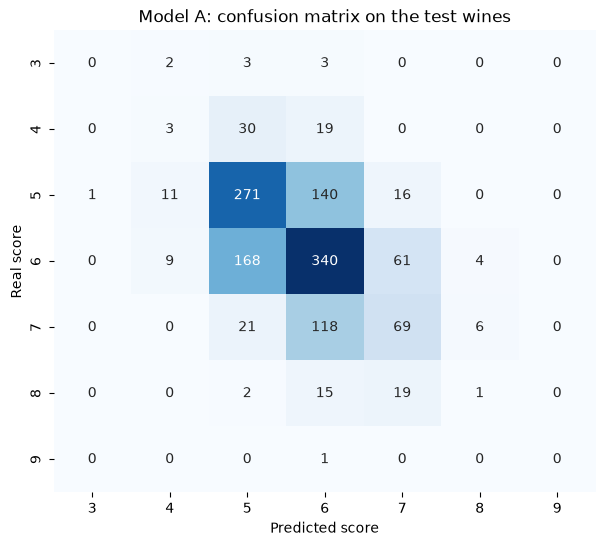

In [12]:
matrix = confusion_matrix(y_test, predicted_scaled, labels=SCORES)
plt.figure(figsize=(7, 6))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=SCORES, yticklabels=SCORES)
plt.xlabel('Predicted score')
plt.ylabel('Real score')
plt.title('Model A: confusion matrix on the test wines')
plt.show()

The confusion matrix has the real score in rows and the predicted score in columns, so the diagonal holds the wines scored correctly and everything off it is a mistake. Nearly all the mass sits in the 5, 6 and 7 block, and the mistakes are one step away: 140 wines that are 5 were called 6, 168 that are 6 were called 5, 118 that are 7 were called 6. The columns for 3 and 9 are empty, the model never predicts them, and the 8 column has 11 wines of which only one is an 8. The model does know that a wine is roughly good or roughly bad. It cannot tell a 7 from an 8, and neither, on these measurements, can anything else.

### Model B: three quality bands and a search for k

The mistakes of Model A are almost all between adjacent scores, and the rare scores cannot be learned from a handful of examples. Both problems are addressed by regrouping the seven scores into three bands: low for scores 3 to 5, medium for 6 and high for 7 to 9. This is a real change of the question, from "what exact score" to "which band", and the results section states what is lost. What is gained is a target with 1,991, 2,327 and 1,011 wines per class, enough for each class to win a vote.

The number of neighbours k is then chosen by 5-fold cross-validation on the training wines: the training set is cut in five parts, the model is fitted on four and scored on the fifth, five times, and the average accuracy is the score of that k. Doing it on the training wines keeps the test wines untouched until the end. Odd values are used so that a vote between three classes can still tie less often, and two ways of measuring distance are compared: euclidean, the straight line, and manhattan, the sum of the absolute differences, which is less dominated by one large difference.

In [13]:
# Regroup the scores into three bands
QUALITY_GROUPS = {3: 'low', 4: 'low', 5: 'low', 6: 'medium', 7: 'high', 8: 'high', 9: 'high'}
CLASSES = ['low', 'medium', 'high']
y_train_band = y_train.map(QUALITY_GROUPS)
y_test_band = y_test.map(QUALITY_GROUPS)
print("Training wines per band:")
print(y_train_band.value_counts().reindex(CLASSES))
print()
print("Share of the largest band in the test set: %.3f" % y_test_band.value_counts(normalize=True).max())

Training wines per band:
quality
low       1492
medium    1745
high       759
Name: count, dtype: int64

Share of the largest band in the test set: 0.437


The training set now has 1,492 low, 1,745 medium and 759 high wines. The medium band is the largest and holds 43.7 percent of the test wines, which is the floor of the evaluation: a model that answers medium to every wine scores 0.437 without reading a single measurement, so any accuracy has to be read against that number.

    euclidean  manhattan
1      0.5350     0.5403
3      0.5393     0.5378
5      0.5498     0.5558
7      0.5668     0.5656
9      0.5648     0.5776
11     0.5771     0.5766
13     0.5828     0.5836
15     0.5823     0.5791
17     0.5853     0.5816
19     0.5856     0.5841
21     0.5851     0.5836
23     0.5836     0.5906
25     0.5871     0.5908
27     0.5813     0.5931
29     0.5866     0.5901
31     0.5811     0.5853
33     0.5846     0.5911
35     0.5833     0.5881
37     0.5866     0.5948
39     0.5831     0.5976
41     0.5848     0.5903
43     0.5833     0.5953
45     0.5873     0.5921
47     0.5906     0.5946
49     0.5876     0.5923
51     0.5896     0.5966

Best: k = 39 with manhattan distance, cross-validated accuracy 0.5976


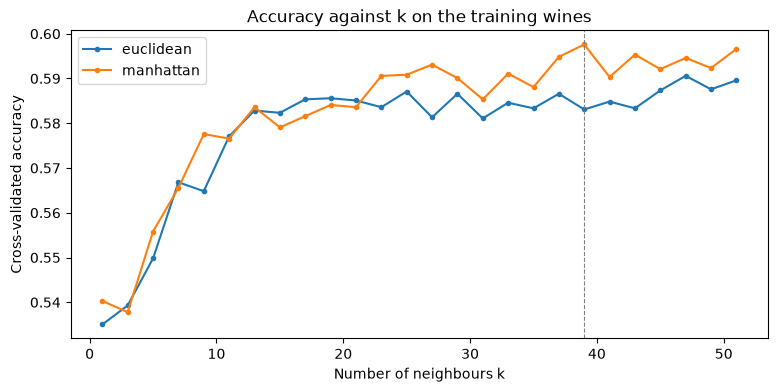

In [14]:
# Cross-validated accuracy for each odd k and each distance
K_VALUES = list(range(1, 52, 2))
DISTANCES = ['euclidean', 'manhattan']
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = pd.DataFrame(index=K_VALUES, columns=DISTANCES, dtype=float)
for k in K_VALUES:
    for distance in DISTANCES:
        candidate = Pipeline([
            ('scale', StandardScaler()),
            ('knn', KNeighborsClassifier(n_neighbors=k, metric=distance)),
        ])
        search.loc[k, distance] = cross_val_score(candidate, X_train, y_train_band, cv=folds).mean()
print(search.round(4))

BEST_DISTANCE = search.max().idxmax()
BEST_K = int(search[BEST_DISTANCE].idxmax())
print()
print("Best: k = %d with %s distance, cross-validated accuracy %.4f" % (BEST_K, BEST_DISTANCE, search.loc[BEST_K, BEST_DISTANCE]))

plt.figure(figsize=(9, 4))
for distance in DISTANCES:
    plt.plot(K_VALUES, search[distance], marker='o', markersize=3, label=distance)
plt.axvline(BEST_K, color='grey', linestyle='--', linewidth=0.8)
plt.xlabel('Number of neighbours k')
plt.ylabel('Cross-validated accuracy')
plt.title('Accuracy against k on the training wines')
plt.legend()
plt.show()

The plot has one line per distance and one point per k. Both lines climb steeply from k equals 1, where the model copies the single nearest wine and scores 0.535, up to about k equals 13, and then flatten into a plateau: from there on adding neighbours changes the accuracy by a few thousandths in either direction. The manhattan line runs slightly above the euclidean one from k equals 23 onward, by about half a point of accuracy, which is consistent with it being less sensitive to one measurement standing far out. The best cell of the table is k equals 39 with the manhattan distance at 0.598, and every k from 23 to 51 with that distance lands within a point of it, so the exact value is not important, what matters is being on the plateau rather than at k equals 5, where the accuracy is four points lower. A small k reads the noise of individual wines and a large k averages it out, and a value near 40 out of 3,996 training wines is still a local vote.

In [15]:
# Refit with the chosen k and distance on all the training wines
model_band = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_DISTANCE)),
]).fit(X_train, y_train_band)
predicted_band = model_band.predict(X_test)
print("Accuracy on the test wines: %.3f" % accuracy_score(y_test_band, predicted_band))
print("Balanced accuracy on the test wines: %.3f" % balanced_accuracy_score(y_test_band, predicted_band))

Accuracy on the test wines: 0.589
Balanced accuracy on the test wines: 0.547


On the 1,333 test wines the model places 58.9 percent in the right band, against the 43.7 percent that answering medium always would give, and its balanced accuracy is 0.547, meaning that on average each band is found a little over half the time. This is a model that knows something and not much, and the confusion matrix says where the knowledge is.

## Evaluation (CRISP-DM 5)

The kept model is Model B. Its confusion matrix and report on the test wines follow, and the comparison with Model A is drawn in the results.

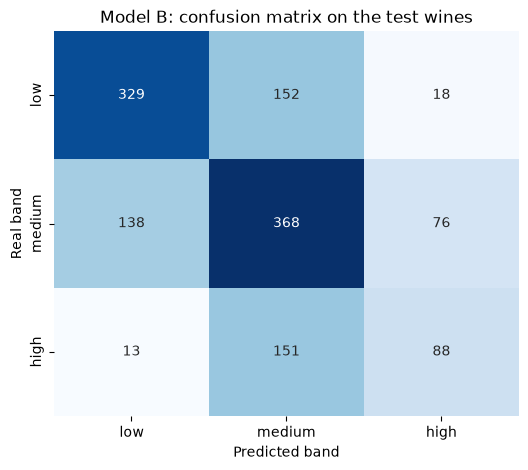

              precision    recall  f1-score   support

         low       0.69      0.66      0.67       499
      medium       0.55      0.63      0.59       582
        high       0.48      0.35      0.41       252

    accuracy                           0.59      1333
   macro avg       0.57      0.55      0.56      1333
weighted avg       0.59      0.59      0.58      1333



In [16]:
matrix_band = confusion_matrix(y_test_band, predicted_band, labels=CLASSES)
plt.figure(figsize=(6, 5))
sns.heatmap(matrix_band, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted band')
plt.ylabel('Real band')
plt.title('Model B: confusion matrix on the test wines')
plt.show()
print(classification_report(y_test_band, predicted_band, labels=CLASSES))

The rows are the real band and the columns the predicted one. The low band is the best served: 329 of its 499 wines are found, a recall of 0.66, and only 18 of them are called high. The medium band has 368 of 582 found, a recall of 0.63, with its mistakes split between low, 138, and high, 76. The high band is the weak one: 88 of 252 found, a recall of 0.35, and 151 of them, six in ten, are called medium. Reading the matrix as a whole, the model rarely confuses low with high, 18 and 13 wines, and its errors are between a band and the one next to it. It separates bad wine from good wine and blurs the line between good and very good, which is the same behaviour Model A showed at a finer grain.

The precision column says what a prediction is worth. When the model says low it is right 69 percent of the time, when it says medium 55 percent, and when it says high 48 percent. The medium band dominates the predictions, 671 of the 1,333 wines are called medium, because it is the largest class and the one that sits between the other two in every measurement, so a wine on either border has medium neighbours.

## Results and Conclusion (CRISP-DM 6: Deployment)

The model kept is a k nearest neighbours classifier with 39 neighbours and the manhattan distance, fitted on the twelve standardized measurements, predicting one of three quality bands. On the 1,333 test wines it reaches an accuracy of 0.589 and a balanced accuracy of 0.547, with a recall of 0.66 for the low band, 0.63 for medium and 0.35 for high, against a floor of 0.437 for a model that always answers medium.

The literal model, seven exact scores with five neighbours, was built and scored first. On standardized values it reaches an accuracy of 0.513 and a balanced accuracy of 0.230, never predicts a 3 or a 9 and finds 3 percent of the 8s. The deviation to three bands costs the exact score: a user asking the assistant gets "high" rather than "7" or "8", and the model cannot separate those two anyway. It buys a target every class of which has enough wines to win a vote, and a model whose mistakes are between neighbouring bands rather than a collapse of the rare scores.

The honest reading is that the laboratory sheet explains part of the tasting score and not most of it. The strongest measurement, alcohol, correlates at 0.47 with the score, the boxes of every measurement overlap across neighbouring scores, and a model that consults 39 similar wines still misplaces four wines in ten. The model is recommended for the assistant as a coarse indicator, useful to flag a batch likely to score low and unreliable at telling a good wine from a very good one, and its answers should be given with the band and not as a score. It is also limited to vinho verde wines, red and white, with measurements inside the range of the training set. The pipeline, the scaler included, is saved below with the predictor list, the band mapping and the fill values, so the REST API can load it and predict without training.

In [17]:
bundle = {
    'model': model_band,
    'features': FEATURES,
    'target': TARGET,
    'classes': CLASSES,
    'quality_groups': QUALITY_GROUPS,
    'fill_values': FILL_VALUES,
    'n_neighbors': BEST_K,
    'distance': BEST_DISTANCE,
}
MODEL_PATH = os.path.join(MODELS_DIR, 'wine_quality_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../../models/wine_quality_classification.joblib


In [18]:
# Reload and classify one wine by hand: a dry white with 13.5 percent alcohol
# and low volatile acidity, the profile the exploration placed at the top
loaded = joblib.load(MODEL_PATH)
example = pd.DataFrame([{
    'type': 1, 'fixed acidity': 6.8, 'volatile acidity': 0.22, 'citric acid': 0.35,
    'residual sugar': 1.8, 'chlorides': 0.035, 'free sulfur dioxide': 30.0,
    'total sulfur dioxide': 110.0, 'density': 0.988, 'pH': 3.2, 'sulphates': 0.5, 'alcohol': 13.5,
}])[loaded['features']]
band = loaded['model'].predict(example)[0]
votes = pd.Series(loaded['model'].predict_proba(example)[0], index=loaded['model'].classes_)
print("Predicted band:", band)
print("Share of the %d neighbours in each band:" % loaded['n_neighbors'])
print(votes.round(3))

Predicted band: high
Share of the 39 neighbours in each band:
high      0.590
low       0.026
medium    0.385
dtype: float64


The reloaded pipeline places this wine in the high band, and the vote shows how firm the answer is: 59 percent of its 39 neighbours are high, 38 percent medium and 3 percent low, and that share is the probability the API can return beside the band. A dry white with 13.5 percent alcohol and little vinegar smell is the profile the box plots put at scores 7 to 9, so the answer matches the exploration, and the 38 percent of medium neighbours is the blur between good and very good seen in the confusion matrix. The API repeats this call: build the twelve columns, fill any gap with the stored values, predict the band and report the share of neighbours behind it.